In [3]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv('DurData_custpurchase.csv')

## Understand the basic structure of the data

In [5]:
df.shape, df.head(), df.columns

((19936, 40),
    Unnamed: 0  Household_ID  N_catg1  N_catg2  N_catg3  N_catg4  N_catg5  \
 0           1     100003544        0        0        0        0        0   
 1           2     100012312        0        0        0        0        0   
 2           3     100016237        0        0        0        0        0   
 3           4     100022945        0        0        0        0        1   
 4           5     100022976        1        0        0        0        0   
 
    N_catg6  N_catg7  N_catg8  ...  E_catg14  E_catg15  Household_Income  \
 0        0        0        0  ...     99.97       0.0               6.0   
 1        0        0        0  ...      0.00       0.0               1.0   
 2        0        0        0  ...      0.00       0.0               NaN   
 3        0        0        2  ...      0.00       0.0               5.0   
 4        0        0        0  ...    249.99       0.0               7.0   
 
    Age_Household_Head  Number_Of_Kids  Total_Number_Of_Transact

In [6]:
basisvars = df[[col for col in df.columns if col.startswith('E_')]]

In [7]:
basisvars.head()

,E_catg1,E_catg2,E_catg3,E_catg4,E_catg5,E_catg6,E_catg7,E_catg8,E_catg9,E_catg10,E_catg11,E_catg12,E_catg13,E_catg14,E_catg15
0,0.00,0.0,0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,99.97,0.0
1,0.00,0.0,0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,19.99,0.00,9.99,0.00,0.0
2,0.00,0.0,0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,89.99,0.00,0.00,0.00,0.0
3,0.00,0.0,0,0.0,259.99,0.0,0.0,24.98,0.0,0.0,193.95,149.99,0.00,0.00,0.0
4,599.99,0.0,0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,249.99,0.0


In [8]:
# choose to work with only the first four columns
basisvars = basisvars.iloc[:, :4]


In [9]:
# calculate the square root of the variance of each column
sd = np.sqrt(basisvars.var())
print (sd)

E_catg1    237.351430
E_catg2     98.408533
E_catg3      0.000000
E_catg4     66.333568
dtype: float64


In [10]:
# given the sd = 0 for the third column, we need to drop it
basisvars = basisvars.drop(basisvars.columns[2], axis=1)

In [11]:
basisvars.head()

,E_catg1,E_catg2,E_catg4
0,0.00,0.0,0.0
1,0.00,0.0,0.0
2,0.00,0.0,0.0
3,0.00,0.0,0.0
4,599.99,0.0,0.0


In [12]:
# Normalize basisvars: (value - mean) / std
basisvars_norm = (basisvars - basisvars.mean()) / sd[basisvars.columns]
basisvars_norm.head()

,E_catg1,E_catg2,E_catg4
0,-0.376114,-0.17634,-0.073835
1,-0.376114,-0.17634,-0.073835
2,-0.376114,-0.17634,-0.073835
3,-0.376114,-0.17634,-0.073835
4,2.151741,-0.17634,-0.073835


## Performing K-means clustering analysis

In [13]:
from sklearn.cluster import KMeans

# Perform k-means clustering with 3 clusters (you can adjust n_clusters as needed)
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(basisvars_norm)

# Add cluster labels to the normalized dataframe
basisvars_norm['cluster'] = clusters

basisvars_norm.head()

,E_catg1,E_catg2,E_catg4,cluster
0,-0.376114,-0.17634,-0.073835,0
1,-0.376114,-0.17634,-0.073835,0
2,-0.376114,-0.17634,-0.073835,0
3,-0.376114,-0.17634,-0.073835,0
4,2.151741,-0.17634,-0.073835,2


In [14]:
# Calculate the size of each cluster
cluster_sizes = basisvars_norm['cluster'].value_counts().sort_index()

# Calculate the average of the variables for each cluster
cluster_means = basisvars_norm.groupby('cluster')[['E_catg1', 'E_catg2', 'E_catg4']].mean()

# Combine the size and means into a single DataFrame
summary = cluster_means.copy()
summary['size'] = cluster_sizes

# Reorder columns to have 'size' first
summary = summary[['size', 'E_catg1', 'E_catg2', 'E_catg4']]
summary

,size,E_catg1,E_catg2,E_catg4
cluster,,,,
0,18334,-0.199401,-0.133744,-0.022979
1,451,0.416157,5.620806,0.170702
2,1151,3.013143,-0.072046,0.299143


## Plot the SSE and find the k-value

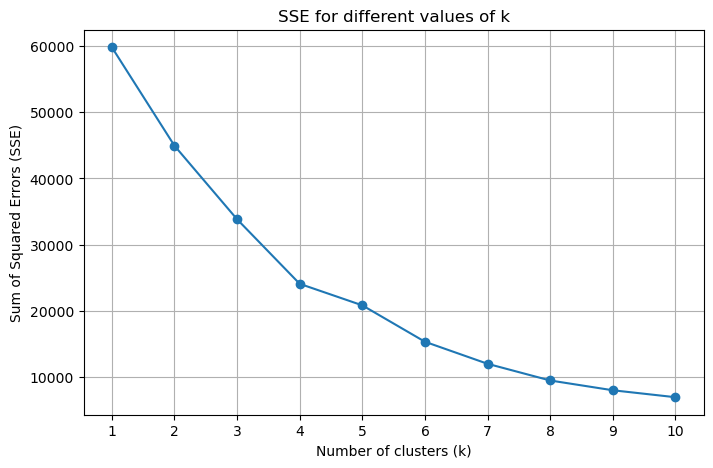

In [15]:
import matplotlib.pyplot as plt

# List of k values to test
max_segments = 10
k_values = range(1, max_segments + 1)
sse = []

# Calculate SSE for each k
for k in k_values:
    kmeans_tmp = KMeans(n_clusters=k, random_state=42)
    kmeans_tmp.fit(basisvars_norm.drop('cluster', axis=1))
    sse.append(kmeans_tmp.inertia_)

# Plot SSE vs k
plt.figure(figsize=(8, 5))
plt.plot(k_values, sse, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Sum of Squared Errors (SSE)')
plt.title('SSE for different values of k')
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Conduct the hierarchical clustering analysis

In [ ]:
# select a subset of the data for easier visualization
df_subset = df[df['Household_ID'] < 100090000]
df_subset.head()

,Unnamed: 0,Household_ID,N_catg1,N_catg2,N_catg3,N_catg4,N_catg5,N_catg6,N_catg7,N_catg8,...,E_catg14,E_catg15,Household_Income,Age_Household_Head,Number_Of_Kids,Total_Number_Of_Transactions,Number_Of_Online_Purchase,Number_Of_Stores_Visited,Number_Of_Returns,Number_Of_Different_Categories
0,1,100003544,0,0,0,0,0,0,0,0,...,99.97,0.0,6.0,28.0,0,1,0,1,0,1
1,2,100012312,0,0,0,0,0,0,0,0,...,0.00,0.0,1.0,24.0,0,1,0,1,0,2
2,3,100016237,0,0,0,0,0,0,0,0,...,0.00,0.0,NaN,NaN,0,1,0,1,0,1
3,4,100022945,0,0,0,0,1,0,0,2,...,0.00,0.0,5.0,44.0,1,1,0,1,2,4
4,5,100022976,1,0,0,0,0,0,0,0,...,249.99,0.0,7.0,54.0,0,1,0,1,0,2


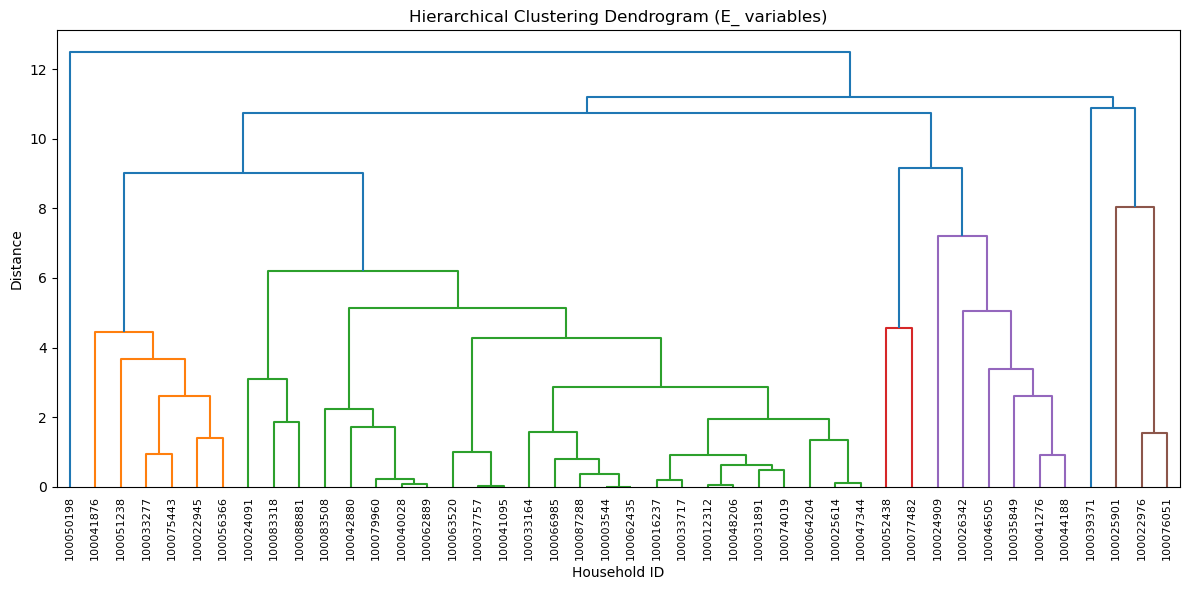

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

import matplotlib.pyplot as plt

# Select columns starting with 'E_' from df_subset
E_cols = [col for col in df_subset.columns if col.startswith('E_')]
X = df_subset[E_cols]

# Drop columns with 0 standard deviation
X = X.drop(X.columns[X.std() == 0], axis=1)  

# Normalize the data
X_normlized = (X - X.mean()) / X.std()

# Perform hierarchical clustering
# the output of linkage is a matrix Z that encodes the hierarchical clustering
# 
Z = linkage(X_normlized, method='ward')

# Plot dendrogram
plt.figure(figsize=(12, 6))
dendrogram(Z, labels=df_subset['Household_ID'].values, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram (E_ variables)')
plt.xlabel('Household ID')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()

The output from linkage(), for the clustering analysis, is a linkage matrix Z, which is a NumPy array with shape (nsamples-1, 4). Each row represents a merge, the columns are [idx1, idx2, distance, sample_count]:
- idx1 and idx2: indices of the merged clusters
- distance: distance between them
- sample_count: number of original observations in the newly formed cluster. 

In [ ]:
# Display the first 5 rows of the linkage matrix
Z[0:5]  

array([[0.00000000e+00, 3.00000000e+01, 2.05330995e-04, 2.00000000e+00],
       [1.50000000e+01, 1.80000000e+01, 1.83864451e-02, 2.00000000e+00],
       [1.00000000e+00, 2.50000000e+01, 5.41661885e-02, 2.00000000e+00],
       [1.70000000e+01, 3.10000000e+01, 7.93218876e-02, 2.00000000e+00],
       [7.00000000e+00, 2.40000000e+01, 1.02963944e-01, 2.00000000e+00]])